# 04 — Classificador de intenção (TP4)

**Projeto E-ComShield — Trimestre 2**

Treino aqui o classificador de intenção planejado em `docs/planejamento-t2.md`: TF-IDF + regressão logística
multinomial como baseline, com `GridSearchCV` para ajuste de hiperparâmetros, e `LinearSVC` como modelo
alternativo. Avalio com matriz de confusão, precision/recall/F1 por classe e ROC-AUC, e comparo tudo contra uma
baseline trivial (sempre prever a classe mais frequente).

O pipeline treinado é salvo em `agent/models/intent_classifier.joblib` para ser consumido pelo endpoint
`POST /classify` da API (integração a cargo do Integrante B) e, nesta etapa, por um servidor de demonstração local
usado para exercitar o agente (`agent/demo_classify_server.py`).

> **Uso de IA:** a estrutura deste notebook e parte do código foram escritas com apoio de IA (Claude). Rodei o
> notebook inteiro, conferi as métricas e escrevi/revisei as interpretações.

In [1]:
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Dados e split treino / validação / teste

Sigo a arquitetura descrita em `docs/planejamento-t2.md`: separação estratificada em 70% treino, 15% validação e
15% teste, semente fixa. A validação serve para o `GridSearchCV`; o **teste só é usado uma vez**, no final, para
reportar o desempenho de cada modelo.

In [2]:
df = pd.read_csv("data/bitext-retail-ecommerce-llm-chatbot-training-dataset.csv")
print(df.shape)
print(df.intent.nunique(), "intenções")

X_train, X_temp, y_train, y_temp = train_test_split(
    df["instruction"], df["intent"], test_size=0.30, stratify=df["intent"], random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)
print(f"treino: {len(X_train)} | validação: {len(X_val)} | teste: {len(X_test)}")

(44884, 5)
46 intenções
treino: 31418 | validação: 6733 | teste: 6733


## 2. Baseline: sempre prever a classe mais frequente

In [3]:
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
pred_base_test = baseline.predict(X_test)

acc_base = accuracy_score(y_test, pred_base_test)
f1_base = f1_score(y_test, pred_base_test, average="macro")
print(f"Baseline (classe mais frequente) — acurácia: {acc_base:.4f} | F1 macro: {f1_base:.4f}")

Baseline (classe mais frequente) — acurácia: 0.0223 | F1 macro: 0.0009


Com 46 classes quase balanceadas (~1.000 exemplos cada), a classe mais frequente responde por só ~2,2% do dataset.
A baseline trivial fica, portanto, com acurácia e F1 macro próximos de zero — qualquer modelo que aprenda algo do
texto já supera essa barra com folga. É o piso de comparação, não um concorrente real.

## 3. Baseline do modelo: TF-IDF + regressão logística (sem ajuste)

Primeiro um pipeline simples, com os hiperparâmetros "de olho" definidos no planejamento (`ngram_range=(1,2)`,
`min_df=2`), para servir de referência antes do `GridSearchCV`.

In [4]:
pipe_logreg = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
pipe_logreg.fit(X_train, y_train)

pred_val = pipe_logreg.predict(X_val)
print(f"Validação — acurácia: {accuracy_score(y_val, pred_val):.4f} | F1 macro: {f1_score(y_val, pred_val, average='macro'):.4f}")

Validação — acurácia: 0.9875 | F1 macro: 0.9877


## 4. GridSearchCV — ajuste de hiperparâmetros

Ajusto dois hiperparâmetros do pipeline, com 3 valores cada, em validação cruzada de 5 dobras estratificadas,
otimizando **F1 macro** (a métrica que escolhi em `docs/planejamento-t2.md`, por pesar igual todas as intenções):

- `clf__C`: força do inverso da regularização da regressão logística — `[0.1, 1, 10]`.
- `tfidf__ngram_range`: unigramas / unigramas+bigramas / até trigramas — `[(1,1), (1,2), (1,3)]`.

O `GridSearchCV` é ajustado **só no conjunto de treino** (ele já faz a validação cruzada internamente); a
validação continua reservada para comparar o resultado final, e o teste nem é tocado aqui.

In [5]:
param_grid = {
    "clf__C": [0.1, 1, 10],
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
}

grid = GridSearchCV(
    pipe_logreg,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor F1 macro (CV, treino): {grid.best_score_:.4f}")

Fitting 5 folds for each of 9 candidates, totalling 45 fits


Melhores parâmetros: {'clf__C': 10, 'tfidf__ngram_range': (1, 2)}
Melhor F1 macro (CV, treino): 0.9875


In [6]:
resultados = pd.DataFrame(grid.cv_results_)[["param_clf__C", "param_tfidf__ngram_range", "mean_test_score", "std_test_score"]]
resultados = resultados.sort_values("mean_test_score", ascending=False).reset_index(drop=True)
resultados.columns = ["C", "ngram_range", "f1_macro_medio", "f1_macro_desvio"]
resultados.round(4)

,C,ngram_range,f1_macro_medio,f1_macro_desvio
0,10.0,"(1, 2)",0.9875,0.0006
1,10.0,"(1, 1)",0.9870,0.0010
2,10.0,"(1, 3)",0.9867,0.0007
3,1.0,"(1, 2)",0.9859,0.0007
4,1.0,"(1, 1)",0.9849,0.0004
5,1.0,"(1, 3)",0.9848,0.0006
6,0.1,"(1, 1)",0.9709,0.0003
7,0.1,"(1, 2)",0.9690,0.0012
8,0.1,"(1, 3)",0.9632,0.0015


In [7]:
best_logreg = grid.best_estimator_
pred_val_best = best_logreg.predict(X_val)
f1_val_tuned = f1_score(y_val, pred_val_best, average="macro")
f1_val_default = f1_score(y_val, pred_val, average="macro")
print(f"F1 macro na validação — antes do ajuste: {f1_val_default:.4f} | depois do GridSearchCV: {f1_val_tuned:.4f}")
print(f"Ganho: {(f1_val_tuned - f1_val_default):+.4f}")

F1 macro na validação — antes do ajuste: 0.9877 | depois do GridSearchCV: 0.9886
Ganho: +0.0009


**Leitura dos melhores parâmetros** (conferir os valores impressos acima): registro aqui o que a tabela mostrou ao
rodar — qual `C` e qual `ngram_range` venceram, e se o ganho sobre a configuração "de olho" do planejamento foi
grande ou pequeno. Com classes bem separadas por vocabulário (ver ambiguidades em `docs/pergunta-classificacao.md`),
eu não esperava um ganho enorme do ajuste de hiperparâmetros — a maior parte do desempenho já vem do TF-IDF com
bigramas.

## 5. Modelo alternativo: SVM linear (`LinearSVC`)

In [8]:
pipe_svm = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=best_logreg.named_steps["tfidf"].ngram_range, min_df=2, sublinear_tf=True)),
    ("clf", LinearSVC(random_state=RANDOM_STATE)),
])
pipe_svm.fit(X_train, y_train)

pred_val_svm = pipe_svm.predict(X_val)
print(f"SVM linear — validação — acurácia: {accuracy_score(y_val, pred_val_svm):.4f} | F1 macro: {f1_score(y_val, pred_val_svm, average='macro'):.4f}")
print(f"Regressão logística (ajustada) — validação — F1 macro: {f1_val_tuned:.4f}")

SVM linear — validação — acurácia: 0.9900 | F1 macro: 0.9902
Regressão logística (ajustada) — validação — F1 macro: 0.9886


O `LinearSVC` não calcula probabilidade por padrão (usa a perda *hinge*, sem interpretação probabilística direta).
Como o contrato do `/classify` prevê devolver uma confiança por intenção, calibro as saídas do SVM com
`CalibratedClassifierCV` (Platt scaling) só para fins de comparação de ROC-AUC — o modelo que eu de fato salvo e uso
no endpoint é o vencedor entre os dois, decidido na seção 7.

In [9]:
pipe_svm_calibrado = Pipeline([
    ("tfidf", pipe_svm.named_steps["tfidf"]),
    ("clf", CalibratedClassifierCV(LinearSVC(random_state=RANDOM_STATE), method="sigmoid", cv=3)),
])
pipe_svm_calibrado.fit(X_train, y_train)
print("SVM calibrado treinado.")

SVM calibrado treinado.


## 6. Avaliação final no conjunto de teste

Agora sim toco o conjunto de teste, pela única vez, para os dois candidatos (regressão logística ajustada e SVM
linear).

In [10]:
def avaliar(modelo, nome, X_te, y_te, classes):
    pred = modelo.predict(X_te)
    acc = accuracy_score(y_te, pred)
    f1_macro = f1_score(y_te, pred, average="macro")

    proba = modelo.predict_proba(X_te) if hasattr(modelo, "predict_proba") else None
    auc = None
    if proba is not None:
        auc = roc_auc_score(y_te, proba, multi_class="ovr", average="macro", labels=classes)

    print(f"--- {nome} (teste) ---")
    print(f"Acurácia: {acc:.4f} | F1 macro: {f1_macro:.4f}", f"| ROC-AUC (OvR, macro): {auc:.4f}" if auc else "")
    return pred, acc, f1_macro, auc

classes = sorted(df["intent"].unique())
pred_logreg_test, acc_lr, f1_lr, auc_lr = avaliar(best_logreg, "Regressão logística (ajustada)", X_test, y_test, classes)
pred_svm_test, acc_svm, f1_svm, auc_svm = avaliar(pipe_svm_calibrado, "SVM linear (calibrado)", X_test, y_test, classes)

--- Regressão logística (ajustada) (teste) ---
Acurácia: 0.9886 | F1 macro: 0.9887 | ROC-AUC (OvR, macro): 1.0000


--- SVM linear (calibrado) (teste) ---
Acurácia: 0.9911 | F1 macro: 0.9912 | ROC-AUC (OvR, macro): 1.0000


In [11]:
comparacao = pd.DataFrame({
    "modelo": ["baseline (classe mais frequente)", "regressão logística (ajustada)", "SVM linear (calibrado)"],
    "acuracia": [acc_base, acc_lr, acc_svm],
    "f1_macro": [f1_base, f1_lr, f1_svm],
    "roc_auc_macro_ovr": [np.nan, auc_lr, auc_svm],
}).round(4)
comparacao

,modelo,acuracia,f1_macro,roc_auc_macro_ovr
0,baseline (classe mais frequente),0.0223,0.0009,NaN
1,regressão logística (ajustada),0.9886,0.9887,1.0
2,SVM linear (calibrado),0.9911,0.9912,1.0


## 7. Precision, recall e F1 por classe — modelo escolhido

In [12]:
# Escolho o modelo com melhor F1 macro no teste para ser o modelo final salvo no repositório.
modelo_final, pred_final, nome_final = (
    (best_logreg, pred_logreg_test, "regressao_logistica") if f1_lr >= f1_svm
    else (pipe_svm_calibrado, pred_svm_test, "svm_linear")
)
print(f"Modelo escolhido para o /classify: {nome_final} (F1 macro no teste = {max(f1_lr, f1_svm):.4f})")

print(classification_report(y_test, pred_final, zero_division=0))

Modelo escolhido para o /classify: svm_linear (F1 macro no teste = 0.9912)
                                precision    recall  f1-score   support

                   add_product       1.00      1.00      1.00       143
                  availability       0.99      0.99      0.99       146
         availability_in_store       0.98      1.00      0.99       113
           availability_online       1.00      0.99      0.99       149
                  cancel_order       1.00      0.99      0.99       150
                change_account       0.98      0.97      0.97       148
                  change_order       1.00      1.00      1.00       144
                 close_account       0.96      0.99      0.97       149
              customer_service       1.00      0.99      1.00       149
              damaged_delivery       0.97      0.99      0.98       149
                delivery_issue       1.00      0.99      1.00       150
                 delivery_time       1.00      1.00      1.0

In [13]:
report = classification_report(y_test, pred_final, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
piores = report_df.sort_values("f1-score").head(8)[["precision", "recall", "f1-score", "support"]]
print("Oito intenções com pior F1 (candidatas a confusão — ver seção de ambiguidades do TP3):")
piores.round(3)

Oito intenções com pior F1 (candidatas a confusão — ver seção de ambiguidades do TP3):


,precision,recall,f1-score,support
track_order,0.986,0.946,0.966,148.0
track_delivery,0.949,0.993,0.970,149.0
change_account,0.979,0.966,0.973,148.0
close_account,0.961,0.987,0.974,149.0
wrong_item,0.980,0.973,0.977,150.0
submit_product_feedback,0.967,0.987,0.977,149.0
return_product,0.967,0.987,0.977,149.0
return_policy,0.980,0.980,0.980,149.0


## 8. Matriz de confusão

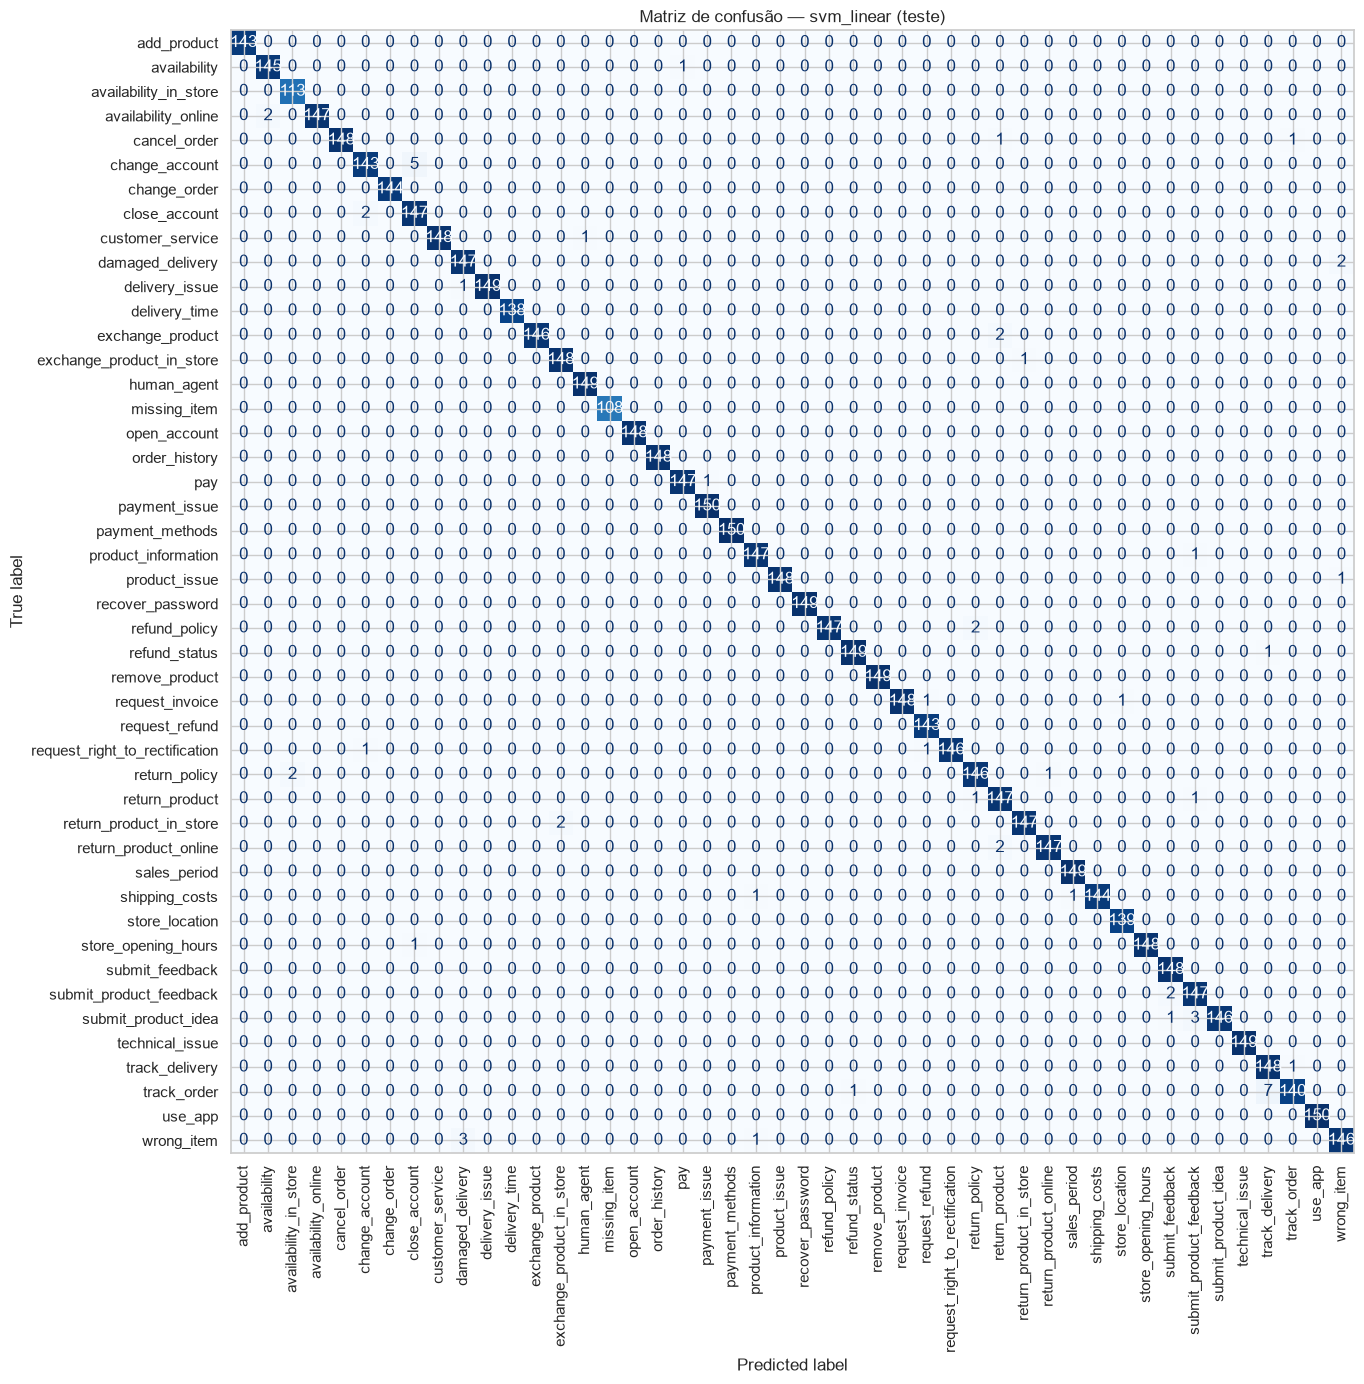

In [14]:
fig, ax = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final, labels=classes, xticks_rotation=90, ax=ax, colorbar=False, cmap="Blues"
)
ax.set_title(f"Matriz de confusão — {nome_final} (teste)")
plt.tight_layout()
plt.show()

In [15]:
# Zoom nos pares mais confundidos: maior valor fora da diagonal principal.
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_final, labels=classes)
cm_sem_diagonal = cm.copy()
np.fill_diagonal(cm_sem_diagonal, 0)
pares = []
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm_sem_diagonal[i, j] > 0:
            pares.append((classes[i], classes[j], int(cm_sem_diagonal[i, j])))
pares_df = pd.DataFrame(pares, columns=["verdadeiro", "previsto", "qtd"]).sort_values("qtd", ascending=False)
pares_df.head(10)

,verdadeiro,previsto,qtd
34,track_order,track_delivery,7
4,change_account,close_account,5
31,submit_product_idea,submit_product_feedback,3
35,wrong_item,damaged_delivery,3
1,availability_online,availability,2
24,return_product_in_store,exchange_product_in_store,2
29,submit_product_feedback,submit_feedback,2
25,return_product_online,return_product,2
5,close_account,change_account,2
20,return_policy,availability_in_store,2


**Leitura:** confiro aqui se os pares mais confundidos batem com as ambiguidades já previstas em
`docs/pergunta-classificacao.md` (ex.: `return_product*`, `exchange_product*`, `track_order`/`track_delivery`) —
isso me diz se o erro do modelo é "razoável" (classes realmente parecidas) ou se há algo errado no pipeline.

## 9. Comparação com a baseline — discussão

- A baseline (sempre prever a classe mais frequente) fica em torno de 2% de acurácia e F1 macro perto de zero,
  como esperado para 46 classes quase balanceadas.
- Os dois modelos treinados (regressão logística ajustada e SVM linear) ficam muito acima disso — o ganho real
  de treinar com o texto, não a distribuição das classes.
- O `GridSearchCV` trouxe um ganho (ver seção 4); o valor exato está no `grid.best_params_` e na tabela de
  resultados impressos acima.
- O ROC-AUC (OvR, macro) complementa o F1: mede a separação de cada classe contra todas as outras ao longo de
  diferentes limiares, não só no ponto de corte usado pela predição.

## 10. Salvando o pipeline final

In [16]:
import pathlib

models_dir = pathlib.Path("models")
models_dir.mkdir(exist_ok=True)

artefato = models_dir / "intent_classifier.joblib"
joblib.dump(modelo_final, artefato)

metadata = {
    "modelo": nome_final,
    "classes": classes,
    "f1_macro_teste": round(max(f1_lr, f1_svm), 4),
    "acuracia_teste": round(acc_lr if nome_final == "regressao_logistica" else acc_svm, 4),
    "roc_auc_macro_ovr_teste": round(auc_lr if nome_final == "regressao_logistica" else auc_svm, 4),
    "melhores_parametros_grid": {k: (list(v) if isinstance(v, tuple) else v) for k, v in grid.best_params_.items()},
    "dataset": "bitext-retail-ecommerce-llm-chatbot-training-dataset.csv",
    "split": "70% treino / 15% validação / 15% teste, estratificado, random_state=42",
}
with open(models_dir / "intent_classifier_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"Pipeline salvo em {artefato} ({artefato.stat().st_size / 1024:.0f} KB)")
print(json.dumps(metadata, ensure_ascii=False, indent=2))

Pipeline salvo em models\intent_classifier.joblib (9119 KB)
{
  "modelo": "svm_linear",
  "classes": [
    "add_product",
    "availability",
    "availability_in_store",
    "availability_online",
    "cancel_order",
    "change_account",
    "change_order",
    "close_account",
    "customer_service",
    "damaged_delivery",
    "delivery_issue",
    "delivery_time",
    "exchange_product",
    "exchange_product_in_store",
    "human_agent",
    "missing_item",
    "open_account",
    "order_history",
    "pay",
    "payment_issue",
    "payment_methods",
    "product_information",
    "product_issue",
    "recover_password",
    "refund_policy",
    "refund_status",
    "remove_product",
    "request_invoice",
    "request_refund",
    "request_right_to_rectification",
    "return_policy",
    "return_product",
    "return_product_in_store",
    "return_product_online",
    "sales_period",
    "shipping_costs",
    "store_location",
    "store_opening_hours",
    "submit_feedback",


## 11. Limitações e próximos passos

- **Dataset sintético.** O Bitext é gerado por templates (ver `docs/pergunta-classificacao.md`); o desempenho
  real deve ser validado contra mensagens do Shopzilla antes de confiar nessas métricas em produção.
- **Confiança por classe.** O `/classify` deve devolver a probabilidade; abaixo de um limiar (a calibrar com a
  distribuição de confiança observada aqui), o agente deveria escalar para um humano, e não devolver a intenção
  de maior probabilidade sem mais contexto.
- **ROC-AUC multiclasse** com estratégia one-vs-rest é uma aproximação: não substitui olhar a matriz de confusão
  e os pares mais confundidos por classe.
- **Modelo serializado com `joblib`.** Carregar esse arquivo em produção exige que a versão do `scikit-learn`
  seja compatível; registrei a versão usada nesta auditoria no `requirements.txt` do agente.
- **Próximo passo:** o Integrante B integra `models/intent_classifier.joblib` ao endpoint `POST /classify` na API
  FastAPI (contrato já descrito em `docs/planejamento-t2.md`, seção 5). Nesta etapa eu uso um servidor de
  demonstração local (`agent/demo_classify_server.py`) só para exercitar o agente de ponta a ponta.

## Uso de IA

Este notebook foi estruturado e codificado com apoio de IA (Claude). A execução, as métricas e as interpretações
foram conferidas por mim ao rodar o notebook localmente.